# ACA N° 2 – Aprendizaje Automático
## Del ML clásico al Deep Learning: predicción del abandono de clientes a partir de su secuencia semanal de compras con redes recurrentes (GRU/LSTM) y un Transformer temporal, desplegada en Streamlit

**Corporación Unificada Nacional de Educación Superior (CUN)** · Escuela de Ingeniería · Especialización en Inteligencia Artificial
**Asignatura:** Aprendizaje Automático · **Docente:** Hamilton Rivera Flor · **Pilar:** Ventas
**Estudiantes:** Juan Guillermo Angel Jaramillo · Luis Bernardo Correa Restrepo · María Alejandra Manga Betancourt

> Continuación del ACA 1 (segmentación RFM con K-Means y predicción de abandono con Random Forest sobre el mismo dataset UCI Online Retail).

## 1. Situación problema, objetivos y dataset

**Pregunta orientadora del ACA 2.** ¿Cómo aprovechar las arquitecturas de redes neuronales (CNN, RNN, Transformers) o modelos de Hugging Face para extraer patrones complejos en datos de ventas, optimizando el rendimiento predictivo y permitiendo su interacción práctica a través de una interfaz en Streamlit?

**Situación problema.** En el ACA 1 predijimos qué clientes de una tienda en línea del Reino Unido **no volverían a comprar** después del 1-sep-2011 (abandono) con un Random Forest sobre tres números por cliente: **recencia, frecuencia y gasto (R-F-M)**. Ese resumen es una *foto*: pierde el **orden y el ritmo** de las compras. Dos clientes con la misma recencia y frecuencia pueden tener trayectorias opuestas (uno acelerando, otro apagándose). En el ACA 2 la red neuronal ve la **película**: la secuencia semanal completa de cada cliente.

**Pregunta adaptada.** ¿Puede una red neuronal que lee la secuencia semanal de compras anticipar el abandono mejor que el Random Forest R-F-M del ACA 1, evaluada con **la misma etiqueta y los mismos clientes de prueba**?

**Objetivos específicos.**
1. Gestionar las transacciones en una base **SQLite** y hacer el EDA y la limpieza con consultas SQL.
2. Construir secuencias semanales por cliente sin fuga de información, con escalado ajustado sólo en entrenamiento y aumento de datos para series.
3. Entrenar y comparar una **GRU**, una **LSTM** y un **encoder Transformer temporal** contra la línea base del ACA 1.
4. Evaluar con curvas por época, ROC/PR, matriz de confusión, IC 95 % por bootstrap, prueba pareada e interpretabilidad (permutación, oclusión por semana y atención).
5. Desplegar el modelo elegido por validación en una app Streamlit con historial en SQLite.

**Dataset.** *Online Retail* (Chen, 2015; UCI Machine Learning Repository, CC BY 4.0): todas las transacciones entre el 1-dic-2010 y el 9-dic-2011 de un minorista en línea del Reino Unido que vende regalos, mayoritariamente a mayoristas. Se usa la copia del paquete R `onlineretail` (archivo `data/raw/onlineretail.rda`).

## 2. Configuración del entorno

In [1]:
import os, json, sqlite3, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import joblib
from torch import nn
from torch.utils.data import DataLoader
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.calibration import calibration_curve
from IPython.display import display, Markdown, Image

from utils.config import *
from utils import db
from utils.secuencias import (construir_series, a_tensor_base, derivar, Escalador, DatasetSecuencias, aumentar,
                              LOG_CANALES)
from utils import modelos as M
from utils.entrenamiento import entrenar, predecir, fijar_semillas, umbral_youden, metricas, bootstrap
from utils.inferencia import preparar, probabilidad, oclusion_semanas
from utils.diagrama import dibujar_todas, ARCHIVO

warnings.filterwarnings("ignore")
# Prueba rápida (1 época, 1 semilla): ACA2_RAPIDO=1 → resultados en carpetas aparte para no pisar los finales
RAPIDO = os.environ.get("ACA2_RAPIDO") == "1"
EPOCAS, SEMILLAS, N_BOOT, N_PERM = (1, [0], 200, 1) if RAPIDO else (80, [0, 1, 2, 3, 4], 2000, 10)
FIG = DIR_FIGURAS / "_rapido" if RAPIDO else DIR_FIGURAS
MOD = DIR_MODELOS / "_rapido" if RAPIDO else DIR_MODELOS
for p in (FIG, MOD):
    p.mkdir(parents=True, exist_ok=True)

torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
fijar_semillas(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight"})
NOMBRES_RED = ["GRU", "LSTM", "Transformer"]
RF = "Random Forest (ACA 1)"
T0 = time.time()
print(f"PyTorch {torch.__version__} · CPU con {torch.get_num_threads()} hilos · semilla {SEED} · corte {FECHA_CORTE.date()}"
      f" · modo {'RÁPIDO (prueba)' if RAPIDO else 'COMPLETO'}")

PyTorch 2.15.0+cpu · CPU con 4 hilos · semilla 42 · corte 2011-09-01 · modo COMPLETO


## 3. PASO 1 – Exploración y gestión de datos en SQL

### 3.1 Carga de las transacciones en SQLite
Se crea `data/ventas.db` con un diseño normalizado:
- `transacciones`: una fila por línea de factura tal como viene en el dataset (sin la descripción, que se repite).
- `productos`: código y descripción de cada producto (la descripción más frecuente del código).
- `clientes`, `series` y `predicciones`: se llenan en los pasos siguientes (ver `utils/db.py`).

In [2]:
if not RUTA_RDA.exists():   # respaldo: copia pública del dataset UCI distribuida en el paquete R "onlineretail"
    import urllib.request
    RUTA_RDA.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve("https://raw.githubusercontent.com/allanvc/onlineretail/master/data/onlineretail.rda", RUTA_RDA)
import pyreadr
raw = pyreadr.read_r(str(RUTA_RDA))["onlineretail"]
raw["InvoiceNo"] = raw["InvoiceNo"].astype(str)
raw["StockCode"] = raw["StockCode"].astype(str)

con = db.conectar(RUTA_DB)
productos = (raw.dropna(subset=["Description"]).groupby("StockCode").Description
             .agg(lambda s: s.mode().iloc[0]).reset_index())
# Tipos compactos: cantidades y clientes enteros, fecha "AAAA-MM-DD HH:MM" (el dataset no registra segundos)
assert (raw.InvoiceDate.dt.second == 0).all() and (raw.Quantity % 1 == 0).all()
trans = raw.drop(columns="Description").assign(InvoiceDate=raw.InvoiceDate.dt.strftime("%Y-%m-%d %H:%M"),
                                               Quantity=raw.Quantity.astype("int64"), CustomerID=raw.CustomerID.astype("Int64"))
trans.to_sql("transacciones", con, if_exists="replace", index=False)
productos.to_sql("productos", con, if_exists="replace", index=False)
con.executescript("""
CREATE INDEX IF NOT EXISTS ix_tr_cliente ON transacciones(CustomerID);
""")
con.commit()
q = lambda sql, params=(): db.consultar(con, sql, params)
q("""SELECT COUNT(*) AS lineas, COUNT(DISTINCT InvoiceNo) AS facturas, COUNT(DISTINCT CustomerID) AS clientes,
          COUNT(DISTINCT StockCode) AS productos, COUNT(DISTINCT Country) AS paises,
          MIN(InvoiceDate) AS desde, MAX(InvoiceDate) AS hasta
   FROM transacciones""")

,lineas,facturas,clientes,productos,paises,desde,hasta
0,541909,25900,4372,4070,38,2010-12-01 08:26,2011-12-09 12:50


In [3]:
pd.DataFrame({
    "columna": list(raw.columns),
    "descripción": ["N.º de factura (6 dígitos; la 'C' inicial indica cancelación/devolución)", "Código del producto (5 dígitos)",
                    "Nombre del producto (tabla productos)", "Cantidad por línea (negativa en devoluciones)",
                    "Fecha y hora de la factura", "Precio unitario en libras (£)", "Identificador del cliente (5 dígitos)",
                    "País de residencia del cliente"],
    "tipo": raw.dtypes.astype(str).values,
})

,columna,descripción,tipo
0,InvoiceNo,N.º de factura (6 dígitos; la 'C' inicial indi...,str
1,StockCode,Código del producto (5 dígitos),str
2,Description,Nombre del producto (tabla productos),str
3,Quantity,Cantidad por línea (negativa en devoluciones),float64
4,InvoiceDate,Fecha y hora de la factura,datetime64[us]
5,UnitPrice,Precio unitario en libras (£),float64
6,CustomerID,Identificador del cliente (5 dígitos),float64
7,Country,País de residencia del cliente,str


### 3.2 Calidad de los datos con SQL

In [4]:
calidad = q("""
SELECT COUNT(*)                                                     AS lineas,
       SUM(CustomerID IS NULL)                                      AS sin_cliente,
       SUM(InvoiceNo LIKE 'C%')                                     AS lineas_cancelacion,
       SUM(Quantity <= 0 AND InvoiceNo NOT LIKE 'C%')               AS cantidad_no_positiva,
       SUM(UnitPrice <= 0)                                          AS precio_no_positivo,
       SUM(NOT (StockCode GLOB '[0-9][0-9][0-9][0-9][0-9]*'))       AS codigos_no_producto
FROM transacciones""")
duplicados = q("""
SELECT SUM(n - 1) AS lineas_duplicadas, COUNT(*) AS grupos_duplicados
FROM (SELECT COUNT(*) AS n FROM transacciones
      GROUP BY InvoiceNo, StockCode, Quantity, InvoiceDate, UnitPrice, CustomerID, Country HAVING n > 1)""")
tabla_calidad = pd.concat([calidad, duplicados], axis=1).T.rename(columns={0: "líneas"})
tabla_calidad["% del total"] = (tabla_calidad["líneas"] / calidad.lineas[0] * 100).round(2)
tabla_calidad

,líneas,% del total
lineas,541909,100.00
sin_cliente,135080,24.93
lineas_cancelacion,9288,1.71
cantidad_no_positiva,1336,0.25
precio_no_positivo,2517,0.46
codigos_no_producto,2995,0.55
lineas_duplicadas,5270,0.97
grupos_duplicados,4881,0.90


In [5]:
q("""SELECT t.StockCode, p.Description, COUNT(*) AS lineas, ROUND(SUM(t.Quantity * t.UnitPrice), 0) AS importe
   FROM transacciones t LEFT JOIN productos p USING (StockCode)
   WHERE NOT (t.StockCode GLOB '[0-9][0-9][0-9][0-9][0-9]*')
   GROUP BY t.StockCode ORDER BY lineas DESC LIMIT 8""")

,StockCode,Description,lineas,importe
0,POST,POSTAGE,1256,66231.0
1,DOT,DOTCOM POSTAGE,710,206245.0
2,M,Manual,571,-68674.0
3,C2,CARRIAGE,144,6986.0
4,D,Discount,77,-5696.0
5,S,SAMPLES,63,-3049.0
6,BANK CHARGES,Bank Charges,37,-7176.0
7,AMAZONFEE,AMAZON FEE,34,-221521.0


**Lectura.** Una cuarta parte de las líneas no tiene cliente (no se pueden atribuir a nadie), hay duplicados exactos de carga, facturas de cancelación (prefijo `C`), precios nulos o negativos (ajustes contables) y códigos que no son productos (portes `POST`, ajustes manuales `M`, comisiones bancarias…). Ninguno de estos registros describe una compra real de un cliente identificado.

### 3.3 EDA de las ventas con SQL

In [6]:
mensual = q("""
SELECT strftime('%Y-%m', InvoiceDate) AS mes,
       SUM(CASE WHEN Country = 'United Kingdom' THEN Quantity * UnitPrice ELSE 0 END) / 1e3 AS reino_unido,
       SUM(CASE WHEN Country <> 'United Kingdom' THEN Quantity * UnitPrice ELSE 0 END) / 1e3 AS otros_paises
FROM transacciones
WHERE InvoiceNo NOT LIKE 'C%' AND Quantity > 0 AND UnitPrice > 0
GROUP BY mes ORDER BY mes""").set_index("mes")
paises = q("""SELECT Country AS pais, COUNT(DISTINCT CustomerID) AS clientes, ROUND(SUM(Quantity*UnitPrice)/1e3,1) AS ventas_miles
             FROM transacciones WHERE InvoiceNo NOT LIKE 'C%' AND Quantity > 0 AND UnitPrice > 0
             GROUP BY pais ORDER BY ventas_miles DESC LIMIT 8""")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
mensual.plot(kind="bar", stacked=True, ax=ax[0], color=["#2E86AB", "#E07A1F"], width=.8)
ax[0].axvline(8.5, color="black", ls="--"); ax[0].text(8.6, mensual.sum(1).max() * .95, "corte 1-sep-2011\n← historia | etiqueta →")
ax[0].set(title="Ventas mensuales (miles de £)", xlabel="", ylabel="miles de £")
ax[1].barh(paises.pais[::-1], paises.ventas_miles[::-1], color="#1B7F79")
ax[1].set(title="Top 8 países por ventas (miles de £)")
fig.tight_layout(); fig.savefig(FIG / "01_ventas_mensuales_pais.png"); plt.show()
q("""SELECT p.Description AS producto, SUM(t.Quantity) AS unidades
   FROM transacciones t JOIN productos p USING (StockCode)
   WHERE t.InvoiceNo NOT LIKE 'C%' AND t.Quantity > 0 AND t.UnitPrice > 0
   GROUP BY t.StockCode ORDER BY unidades DESC LIMIT 5""")

,producto,unidades
0,"PAPER CRAFT , LITTLE BIRDIE",80995
1,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,POPCORN HOLDER,56921
3,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047
4,JUMBO BAG RED RETROSPOT,48474


**Lectura.** Las ventas crecen hacia la temporada navideña y dependen del Reino Unido. Diciembre de 2011 está incompleto (el dataset termina el día 9). Igual que en el ACA 1, el **corte del 1-sep-2011** separa la historia observada (40 semanas) de la ventana en la que se mide si el cliente vuelve (≈ 100 días).

### 3.4 Limpieza con vistas SQL
La limpieza replica exactamente la del ACA 1 y queda declarada en SQL (vistas, sin duplicar datos):
1. `lineas_unicas`: sin duplicados exactos y sólo con cliente identificado.
2. `ventas_limpias`: sin cancelaciones, con cantidad y precio > 0 y sólo códigos de producto (5 dígitos).
3. `cancelaciones`: facturas con prefijo `C` del cliente, que se conservan aparte como **devoluciones**.

In [7]:
con.executescript("""
DROP VIEW IF EXISTS lineas_unicas; DROP VIEW IF EXISTS ventas_limpias; DROP VIEW IF EXISTS cancelaciones;
CREATE VIEW lineas_unicas AS
    SELECT DISTINCT InvoiceNo, StockCode, Quantity, InvoiceDate, UnitPrice, CAST(CustomerID AS INTEGER) AS CustomerID, Country
    FROM transacciones WHERE CustomerID IS NOT NULL;
CREATE VIEW ventas_limpias AS
    SELECT * FROM lineas_unicas
    WHERE InvoiceNo NOT LIKE 'C%' AND Quantity > 0 AND UnitPrice > 0
      AND StockCode GLOB '[0-9][0-9][0-9][0-9][0-9]*';
CREATE VIEW cancelaciones AS SELECT * FROM lineas_unicas WHERE InvoiceNo LIKE 'C%';
""")
pasos = q("""
SELECT 'Dataset original' AS paso, COUNT(*) AS lineas FROM transacciones
UNION ALL SELECT 'Sin duplicados y con cliente', COUNT(*) FROM lineas_unicas
UNION ALL SELECT 'Ventas limpias (sin cancelaciones, cantidad y precio > 0, sólo productos)', COUNT(*) FROM ventas_limpias
UNION ALL SELECT 'Líneas de cancelación (devoluciones, aparte)', COUNT(*) FROM cancelaciones""")
pasos["% del original"] = (pasos.lineas / pasos.lineas[0] * 100).round(1)
pasos

,paso,lineas,% del original
0,Dataset original,541909,100.0
1,Sin duplicados y con cliente,401602,74.1
2,"Ventas limpias (sin cancelaciones, cantidad y ...",391148,72.2
3,"Líneas de cancelación (devoluciones, aparte)",8872,1.6


In [8]:
corte = str(FECHA_CORTE.date())
lineas = q("SELECT * FROM ventas_limpias WHERE InvoiceDate < ?", (corte,))
canc = q("SELECT * FROM cancelaciones WHERE InvoiceDate < ?", (corte,))
for df in (lineas, canc):
    df["InvoiceDate"] = pd.to_datetime(df.InvoiceDate)
vuelven = set(q("SELECT DISTINCT CustomerID FROM ventas_limpias WHERE InvoiceDate >= ?", (corte,)).CustomerID)

# Tabla de clientes: R-F-M exactos calculados en SQL + país + etiqueta
clientes = q("""
SELECT CustomerID,
       CAST(julianday(?) - julianday(MAX(InvoiceDate)) AS INTEGER) AS recencia_dias,
       COUNT(DISTINCT InvoiceNo)                                  AS frecuencia,
       SUM(Quantity * UnitPrice)                                  AS monetario
FROM ventas_limpias WHERE InvoiceDate < ? GROUP BY CustomerID ORDER BY CustomerID""", (corte, corte))
clientes["pais"] = clientes.CustomerID.map(lineas.groupby("CustomerID").Country.agg(lambda s: s.mode().iloc[0]))
clientes["abandono"] = (~clientes.CustomerID.isin(vuelven)).astype(int)   # 1 = NO volvió a comprar tras el corte

# Verificación contra la tabla exportada por el ACA 1 (misma población, misma etiqueta)
aca1 = pd.read_csv(RUTA_ACA1)
assert (clientes.CustomerID.to_numpy() == aca1.CustomerID.to_numpy()).all(), "Los clientes no coinciden con el ACA 1"
assert (clientes.abandono.to_numpy() == aca1.abandono.to_numpy()).all(), "La etiqueta no coincide con el ACA 1"
assert (clientes.recencia_dias.to_numpy() == aca1.recencia_dias.to_numpy()).all()
assert (clientes.frecuencia.to_numpy() == aca1.frecuencia.to_numpy()).all()
dif_m = np.abs(clientes.monetario.to_numpy() - aca1.monetario.to_numpy())
# El DISTINCT de SQL compara la línea sin la descripción del producto; el ACA 1 (pandas) la incluía. Si dos líneas sólo
# difieren en el texto de la descripción, SQL las trata como duplicado (lo cual es correcto) y el gasto cambia un poco.
print(f"Gasto total: {(dif_m > 0.05).sum()} cliente(s) con diferencia > £0,05 respecto al ACA 1 (máx. £{dif_m.max():.2f}) "
      "por líneas duplicadas que sólo cambiaban en la descripción")
assert (dif_m > 0.05).sum() <= 5 and dif_m.max() < 50
clientes["segmento"] = aca1.segmento.to_numpy()
print(f"Clientes: {len(clientes):,} (idénticos al ACA 1) · tasa de abandono: {clientes.abandono.mean():.1%}")
clientes.head()

Gasto total: 1 cliente(s) con diferencia > £0,05 respecto al ACA 1 (máx. £14.85) por líneas duplicadas que sólo cambiaban en la descripción
Clientes: 3,314 (idénticos al ACA 1) · tasa de abandono: 41.2%


,CustomerID,recencia_dias,frecuencia,monetario,pais,abandono,segmento
0,12346,225,1,77183.60,United Kingdom,1,En riesgo
1,12347,29,5,2790.86,Iceland,0,En riesgo
2,12348,148,3,1167.24,Finland,0,En riesgo
3,12350,210,1,294.40,Norway,1,Dormidos
4,12352,162,4,641.51,Norway,0,En riesgo


### 3.5 De transacciones a secuencias semanales (tabla `series`)
Cada cliente se representa con **40 semanas** de historia (1-dic-2010 → 31-ago-2011). La semana 39 son los 7 días previos al corte. Por semana se guardan 5 canales base: **gasto (£), pedidos, unidades, productos distintos y devoluciones**. A partir de ellos se derivan (en `utils/secuencias.py`, la misma función para el notebook y la app) dos canales más: **días sin comprar** al cierre de cada semana y un indicador **ya es cliente**, además de las variables estáticas **R-F-M** de la propia secuencia.

In [9]:
serie = construir_series(lineas, canc)
db.guardar_tabla(con, "clientes", clientes[["CustomerID", "pais", "recencia_dias", "frecuencia", "monetario",
                                           "segmento", "abandono"]])
n_filas = db.guardar_tabla(con, "series", serie)
print(f"Tabla series: {n_filas:,} filas (cliente × semana con actividad); el resto de semanas vale 0")
q("""SELECT c.abandono,
          COUNT(DISTINCT c.CustomerID)                         AS clientes,
          ROUND(1.0 * COUNT(s.semana) / COUNT(DISTINCT c.CustomerID), 2) AS semanas_activas_por_cliente,
          ROUND(AVG(s.gasto), 1)                               AS gasto_medio_semana_activa,
          ROUND(1.0 * SUM(s.semana >= 27) / COUNT(DISTINCT c.CustomerID), 2) AS semanas_activas_ultimo_trimestre
   FROM clientes c JOIN series s USING (CustomerID) GROUP BY c.abandono""")

Tabla series: 11,039 filas (cliente × semana con actividad); el resto de semanas vale 0


,abandono,clientes,semanas_activas_por_cliente,gasto_medio_semana_activa,semanas_activas_ultimo_trimestre
0,0,1947,4.35,495.6,1.57
1,1,1367,1.84,376.6,0.57


In [10]:
ids = clientes.CustomerID.to_numpy()
y = clientes.abandono.to_numpy()
base = a_tensor_base(serie, ids)                 # (clientes, 40 semanas, 5 canales) en unidades originales
completo, estaticas = derivar(base)
pedidos_cli = base[:, :, 1].sum(1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
bins = [1, 2, 3, 4, 6, 10, 20, 400]
for k, nom in enumerate(CLASES):
    ax[0].hist(np.clip(pedidos_cli[y == k], 1, 399), bins=bins, alpha=.6, color=COLORES[nom], label=nom, density=True)
ax[0].set(xscale="log", title="Pedidos por cliente antes del corte", xlabel="pedidos (escala log)", ylabel="densidad"); ax[0].legend()
semanas = np.arange(N_SEMANAS)
for k, nom in enumerate(CLASES):
    ax[1].plot(semanas, (base[y == k, :, 1] > 0).mean(0) * 100, color=COLORES[nom], lw=2, label=nom)
    ax[2].plot(semanas, base[y == k, :, 0].mean(0), color=COLORES[nom], lw=2, label=nom)
ax[1].set(title="% de clientes que compran cada semana", xlabel="semana (39 = última antes del corte)", ylabel="%")
ax[2].set(title="Gasto medio por semana (£)", xlabel="semana", ylabel="£"); ax[1].legend(); ax[2].legend()
fig.tight_layout(); fig.savefig(FIG / "02_perfil_semanal.png"); plt.show()
pd.Series({"Clientes con un solo pedido": f"{(pedidos_cli == 1).mean():.1%}",
           "Mediana de semanas con compra": int(np.median((base[:, :, 1] > 0).sum(1))),
           "Celdas cliente×semana sin actividad": f"{(base[:, :, 1] == 0).mean():.1%}"}).to_frame("valor")

,valor
Clientes con un solo pedido,41.6%
Mediana de semanas con compra,2
Celdas cliente×semana sin actividad,92.6%


In [11]:
rng = np.random.default_rng(SEED)
muestra = np.concatenate([rng.choice(np.flatnonzero((y == k) & (pedidos_cli >= 3)), 30, replace=False) for k in (0, 1)])
fig, ax = plt.subplots(figsize=(15, 5.5))
sns.heatmap(np.log1p(base[muestra, :, 0]), cmap="Oranges", cbar_kws={"label": "log(1 + gasto semanal)"}, ax=ax,
            yticklabels=False)
ax.axhline(30, color="black", lw=2)
ax.text(40.5, 15, "Recompra", va="center", color=COLORES["Recompra"], fontweight="bold")
ax.text(40.5, 45, "Abandono", va="center", color=COLORES["Abandono"], fontweight="bold")
ax.set(title="La «película» de 60 clientes con ≥ 3 pedidos (filas) a lo largo de 40 semanas", xlabel="semana", ylabel="clientes")
fig.savefig(FIG / "03_mapa_clientes_semanas.png"); plt.show()

**Lectura.** Las secuencias son **muy dispersas**: la mayoría de las semanas de un cliente están vacías y una fracción grande de clientes compró una sola vez. Aun así, los que abandonan concentran su actividad al inicio de la ventana y se van «apagando» hacia el corte, mientras los que recompran mantienen un ritmo regular hasta el final. Ese patrón temporal es lo que la red debe aprender, más allá de los totales R-F-M.

## 4. PASO 2 – Preparación y pipeline

### 4.1 Partición sin fuga (idéntica a la del ACA 1)
- **Misma partición de prueba que el ACA 1:** `train_test_split(test_size=0.20, stratify=y, random_state=42)` sobre los mismos clientes en el mismo orden → los mismos clientes de prueba.
- **Validación:** 15 % del entrenamiento (estratificado, por cliente). Se usa para early stopping, el umbral y la **selección del modelo de la app**. La prueba sólo se usa para reportar.
- **Sin fuga temporal:** las secuencias usan sólo transacciones anteriores al corte; la etiqueta sólo posteriores. `semana_de()` lanza un error si recibe una fecha ≥ corte.
- **Sin fuga entre clientes:** cada cliente está en una sola partición (se verifica con conjuntos y con SQL).

In [12]:
idx_tr_total, idx_te = train_test_split(np.arange(len(ids)), test_size=.20, stratify=y, random_state=SEED)
idx_tr, idx_va = train_test_split(idx_tr_total, test_size=.15, stratify=y[idx_tr_total], random_state=SEED)
particion = {**{c: "train" for c in ids[idx_tr]}, **{c: "val" for c in ids[idx_va]}, **{c: "test" for c in ids[idx_te]}}
db.asignar_particion(con, particion)

# Verificaciones de no-fuga
assert lineas.InvoiceDate.max() < FECHA_CORTE and canc.InvoiceDate.max() < FECHA_CORTE
assert not (set(ids[idx_tr]) & set(ids[idx_va]) or set(ids[idx_tr]) & set(ids[idx_te]) or set(ids[idx_va]) & set(ids[idx_te]))
assert len(idx_tr) + len(idx_va) + len(idx_te) == len(ids)
print("Última fecha usada para construir X:", lineas.InvoiceDate.max(), "< corte", FECHA_CORTE.date())
q("""SELECT particion, COUNT(*) AS clientes, ROUND(100.0 * AVG(abandono), 1) AS pct_abandono
   FROM clientes GROUP BY particion ORDER BY CASE particion WHEN 'train' THEN 1 WHEN 'val' THEN 2 ELSE 3 END""")

Última fecha usada para construir X: 2011-08-31 17:16:00 < corte 2011-09-01


,particion,clientes,pct_abandono
0,train,2253,41.3
1,val,398,41.2
2,test,663,41.2


### 4.2 Escalado (ajustado sólo con entrenamiento)
Los canales de conteo y dinero tienen cola larga: se aplica `log(1+x)` y luego estandarización con la media y la desviación **del conjunto de entrenamiento** (sin validación ni prueba). El indicador *ya es cliente* (0/1) se deja igual. Los parámetros se guardan en `modelos/escalador.json` y la app los usa tal cual.

In [13]:
esc = Escalador().ajustar(base[idx_tr])
esc.guardar(MOD / "escalador.json")
seq_all, est_all = esc.transformar(base)
resumen_esc = pd.DataFrame({
    "canal": [ETIQUETAS[c] for c in CANALES],
    "log(1+x)": [c in LOG_CANALES for c in CANALES],
    "media train (escalado)": seq_all[idx_tr].reshape(-1, len(CANALES)).mean(0),
    "desv. train (escalado)": seq_all[idx_tr].reshape(-1, len(CANALES)).std(0),
    "media prueba (escalado)": seq_all[idx_te].reshape(-1, len(CANALES)).mean(0)})
resumen_esc.round(3)

,canal,log(1+x),media train (escalado),desv. train (escalado),media prueba (escalado)
0,Gasto (£),True,-0.00,0.999,-0.023
1,Pedidos,True,-0.00,1.000,-0.020
2,Unidades,True,-0.00,1.000,-0.022
3,Productos distintos,True,-0.00,1.000,-0.015
4,Devoluciones,True,0.00,1.000,-0.011
5,Días sin comprar,True,-0.00,1.000,0.012
6,Ya es cliente,False,0.64,0.480,0.637


### 4.3 Aumento de datos para series (sólo entrenamiento)
Con pocos miles de clientes, el aumento regulariza la red. Se aplica **en línea**, cada vez que la red ve un cliente, sobre los canales base y **antes** de derivar días sin comprar y R-F-M. Así la secuencia aumentada sigue siendo coherente:
- **Escalado aleatorio** del gasto y las unidades (factor log-normal, σ = 0,15): el mismo comportamiento con tickets algo mayores o menores.
- **Jitter** multiplicativo (σ = 0,10) sólo en semanas con compra: nunca crea actividad donde no la hubo.
- **Recorte de ventana**: se borran las *k* semanas más antiguas sin vaciar la serie, como si el cliente fuera más nuevo.

No se usan desplazamientos en el tiempo ni inversión, porque cambiarían la recencia, que define la etiqueta.

In [14]:
rng_demo = np.random.default_rng(3)
cand = idx_tr[(base[idx_tr, :, 1] > 0).sum(1) >= 6]
i_demo = cand[0]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.4), sharey=True)
ax[0].bar(semanas, base[i_demo, :, 0], color="#2E86AB"); ax[0].set_title(f"Original (cliente {ids[i_demo]})")
for k in range(1, 4):
    aum = aumentar(base[i_demo], rng_demo, p=1.0)
    ax[k].bar(semanas, aum[:, 0], color="#E07A1F"); ax[k].set_title(f"Aumento {k}")
for a in ax:
    a.set_xlabel("semana")
ax[0].set_ylabel("gasto semanal (£)")
fig.suptitle("Aumento de datos sobre la serie de gasto (escalado + jitter + recorte de ventana)", y=1.04)
fig.savefig(FIG / "04_aumento_datos.png"); plt.show()

### 4.4 Desbalance de clases
Los abandonos son la clase minoritaria. En lugar de sobremuestrear (que duplicaría clientes), la pérdida usa `pos_weight = n_negativos / n_positivos` del entrenamiento y el umbral de decisión se elige en validación con la misma regla de Youden del ACA 1.

In [15]:
p_tr = y[idx_tr].mean()
POS_WEIGHT = float((1 - p_tr) / p_tr)
BATCH = 64
ds_va = DatasetSecuencias(base[idx_va], y[idx_va], esc)
ds_te = DatasetSecuencias(base[idx_te], y[idx_te], esc)
dl_va = DataLoader(ds_va, batch_size=512)
dl_te = DataLoader(ds_te, batch_size=512)
print(f"Abandono en train: {p_tr:.1%} → pos_weight = {POS_WEIGHT:.3f}")
print(f"Tensores de entrada: secuencia {tuple(ds_te.seq.shape[1:])} (semanas × canales) + estáticas {tuple(ds_te.est.shape[1:])}")

Abandono en train: 41.3% → pos_weight = 1.423
Tensores de entrada: secuencia (40, 7) (semanas × canales) + estáticas (3,)


## 5. PASO 3 – Modelado con redes neuronales

### 5.1 Línea base: el Random Forest del ACA 1
Se carga el modelo exportado por el ACA 1 y se comprueba que reproduce su ROC-AUC en prueba. Luego se reentrena el mismo pipeline (mismos hiperparámetros y semilla) con el mismo entrenamiento para guardarlo junto a las redes.

In [16]:
# Modelo propio del equipo (exportado por el ACA 1 y copiado en aca1/): fuente de confianza
aca1_art = joblib.load(BASE / "aca1" / "modelo_abandono_clientes.joblib")
aca1_met = json.loads((BASE / "aca1" / "metricas.json").read_text(encoding="utf-8"))
COLS_RF = aca1_art["variables"]
X_rf = aca1[COLS_RF]          # mismas variables exactas con las que se entrenó el RF del ACA 1
p_rf_aca1 = aca1_art["pipeline"].predict_proba(X_rf.iloc[idx_te])[:, 1]
rf = clone(aca1_art["pipeline"]).fit(X_rf.iloc[idx_tr_total], y[idx_tr_total])
p_rf = {"val": rf.predict_proba(X_rf.iloc[idx_va])[:, 1], "test": rf.predict_proba(X_rf.iloc[idx_te])[:, 1]}
assert np.allclose(p_rf["test"], p_rf_aca1), "El RF reentrenado no reproduce al del ACA 1"
assert abs(roc_auc_score(y[idx_te], p_rf["test"]) - aca1_met["metricas_test"]["roc_auc"]) < 1e-3
joblib.dump({"pipeline": rf, "variables": COLS_RF, "umbral": aca1_art["umbral"]}, MOD / "random_forest_aca1.joblib", compress=3)
print(f"RF del ACA 1 · variables {COLS_RF} · umbral {aca1_art['umbral']} · "
      f"ROC-AUC prueba {roc_auc_score(y[idx_te], p_rf['test']):.4f} (ACA 1: {aca1_met['metricas_test']['roc_auc']})")

RF del ACA 1 · variables ['recencia_dias', 'frecuencia', 'monetario'] · umbral 0.38 · ROC-AUC prueba 0.7197 (ACA 1: 0.7197)


### 5.2 Arquitecturas y justificación
| Red | Por qué |
|---|---|
| **GRU** (2 capas, 32 unidades) | Recurrente con compuertas de actualización y reinicio: decide qué recordar del pasado. Pocos parámetros, adecuada para secuencias cortas (40 pasos) y pocos miles de ejemplos. |
| **LSTM** (2 capas, 32 unidades) | Variante con celda de memoria y 3 compuertas; sirve para comprobar si más capacidad de memoria aporta. |
| **Transformer temporal** (2 bloques, 4 cabezas, d = 32) | Cada semana es un *token*. La autoatención relaciona todas las semanas entre sí sin pasar por una cadena recurrente. Un token `[CLS]` resume al cliente y su atención es interpretable. |

Las tres redes comparten la **cabeza híbrida**: concatenan su resumen de la secuencia con R-F-M (derivados de la misma secuencia) y pasan por una capa densa con dropout hasta una salida sigmoide. Cada arquitectura se entrena con **5 semillas** y se promedian sus probabilidades (ensamble), lo que reduce la varianza propia de un conjunto pequeño. Se usó un encoder propio en lugar de un modelo preentrenado de Hugging Face porque esos modelos están pensados para texto o para series densas y largas, no para 40 semanas dispersas. Además, el encoder propio pesa unos pocos kB y la app funciona sin internet.

**Entrenamiento:** AdamW (lr 2·10⁻³, weight decay 10⁻³), `ReduceLROnPlateau` sobre el ROC-AUC de validación, recorte de gradiente, early stopping (paciencia 12) y restauración de la mejor época.

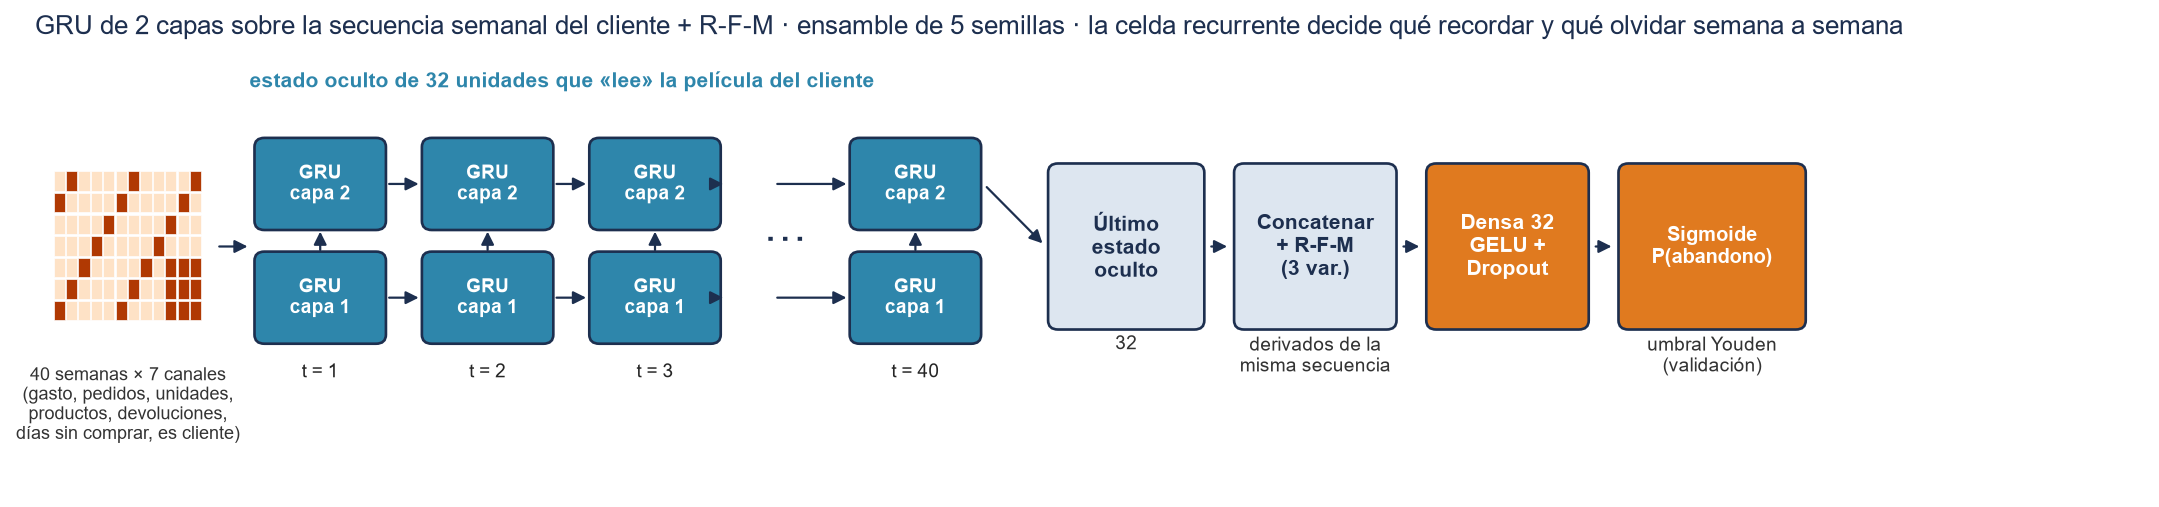

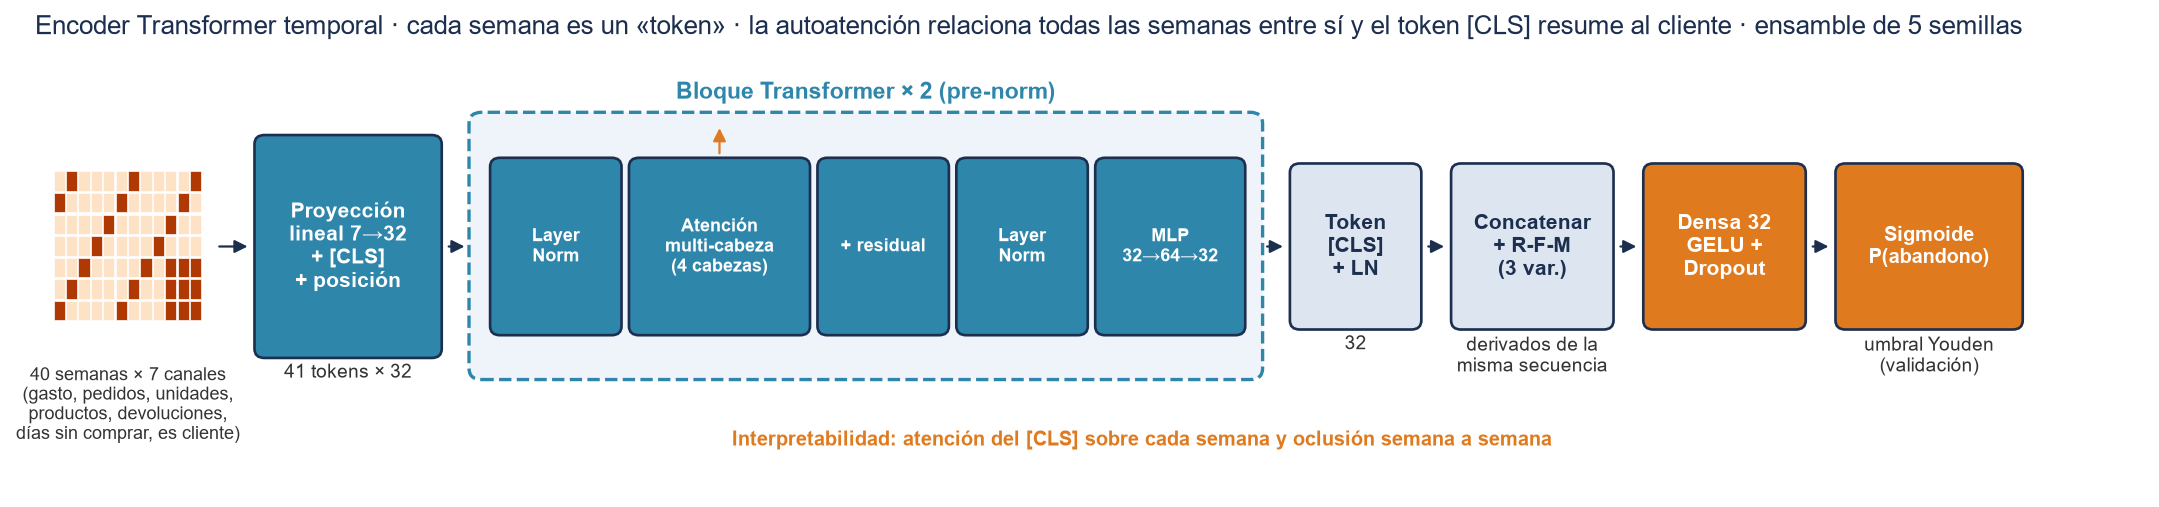

,parámetros por red,descripción
GRU,11457,Red recurrente GRU de 2 capas (32 unidades) + ...
LSTM,14881,Red recurrente LSTM de 2 capas (32 unidades) +...
Transformer,19937,"Encoder Transformer temporal (2 bloques, 4 cab..."


In [17]:
for r in dibujar_todas():
    pass
display(Image(filename=str(DIR_FIGURAS / ARCHIVO["GRU"]), width=1000))
display(Image(filename=str(DIR_FIGURAS / ARCHIVO["Transformer"]), width=1000))
pd.DataFrame({n: {"parámetros por red": M.n_parametros(M.crear(n)), "descripción": M.DESCRIPCION[n]} for n in NOMBRES_RED}).T

### 5.3 Revisión de la pérdida inicial
Antes de entrenar se comprueba que la pérdida de partida es la esperada. La última capa se inicializa con pesos ≈ 0 y sesgo 0, así que la red arranca prediciendo P = 0,5. Con `pos_weight` la BCE ponderada esperada es ln 2 · (p·w + 1 − p). Si la pérdida inicial fuera mucho mayor, el problema estaría en la inicialización de la cabeza, el escalado o la tasa de aprendizaje, no en la arquitectura.

In [18]:
crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT))
esperada = np.log(2) * (p_tr * POS_WEIGHT + 1 - p_tr)
ds_tr_chk = DatasetSecuencias(base[idx_tr], y[idx_tr], esc)
seq_c, est_c, y_c = ds_tr_chk.seq, ds_tr_chk.est, ds_tr_chk.y
filas = []
for n in NOMBRES_RED:
    fijar_semillas(0)
    with torch.no_grad():
        l = crit(M.crear(n)(torch.from_numpy(seq_c), torch.from_numpy(est_c)), torch.from_numpy(y_c)).item()
    filas.append({"red": n, "pérdida inicial (train)": l, "esperada": esperada})
perdida_inicial = pd.DataFrame(filas).set_index("red")
assert (abs(perdida_inicial["pérdida inicial (train)"] - esperada) < 0.05).all(), "Pérdida inicial anómala"
perdida_inicial.round(4)

,pérdida inicial (train),esperada
red,,
GRU,0.8137,0.8141
LSTM,0.8133,0.8141
Transformer,0.8126,0.8141


### 5.4 Entrenamiento (3 arquitecturas × 5 semillas)

In [19]:
RES = {}
for nombre in NOMBRES_RED:
    miembros, hists, t_arq = [], [], time.time()
    for s in SEMILLAS:
        fijar_semillas(s)
        ds_tr = DatasetSecuencias(base[idx_tr], y[idx_tr], esc, aumentar_datos=True, seed=s)
        dl_tr = DataLoader(ds_tr, batch_size=BATCH, shuffle=True, generator=torch.Generator().manual_seed(s))
        red = M.crear(nombre)
        h = entrenar(red, dl_tr, dl_va, epocas=EPOCAS, pos_weight=POS_WEIGHT, verbose=(s == SEMILLAS[0]),
                     nombre=f"{nombre} s{s}")
        mejor = max(h, key=lambda e: e["auc_val"])
        print(f"  {nombre} semilla {s}: {len(h)} épocas · pérdida ép. 1 = {h[0]['loss_train']:.3f} · "
              f"mejor AUC val = {mejor['auc_val']:.4f} (ép. {mejor['epoca']}) · {sum(e['seg'] for e in h):.0f}s")
        miembros.append(red); hists.append(h)
    ens = M.Ensamble(miembros).eval()
    M.guardar(miembros, nombre, MOD / f"{nombre.lower()}_abandono.pt", semillas=SEMILLAS)
    RES[nombre] = {"modelo": ens, "hist": hists, "parametros": M.n_parametros(miembros[0]),
                   "auc_val_semillas": [max(e["auc_val"] for e in h) for h in hists],
                   "epocas": [len(h) for h in hists], "seg": time.time() - t_arq}
    print(f"→ {nombre}: pesos de las {len(miembros)} semillas en {MOD / (nombre.lower() + '_abandono.pt')} · "
          f"{RES[nombre]['seg'] / 60:.1f} min\n")

[GRU s0] ép 01 | loss 0.763/0.564 | acc 0.624/0.719 | AUC 0.681/0.761 | lr 2.0e-03 | 1.7s


[GRU s0] ép 02 | loss 0.713/0.554 | acc 0.652/0.704 | AUC 0.716/0.772 | lr 2.0e-03 | 1.8s


[GRU s0] ép 03 | loss 0.699/0.582 | acc 0.653/0.676 | AUC 0.735/0.769 | lr 2.0e-03 | 1.7s


[GRU s0] ép 04 | loss 0.702/0.549 | acc 0.647/0.704 | AUC 0.730/0.773 | lr 2.0e-03 | 2.3s


[GRU s0] ép 05 | loss 0.703/0.555 | acc 0.652/0.696 | AUC 0.729/0.771 | lr 2.0e-03 | 1.8s


[GRU s0] ép 06 | loss 0.697/0.563 | acc 0.656/0.683 | AUC 0.732/0.772 | lr 2.0e-03 | 2.2s


... (61 outputs left out)

  Transformer semilla 1: 32 épocas · pérdida ép. 1 = 0.763 · mejor AUC val = 0.7674 (ép. 20) · 110s


  Transformer semilla 2: 13 épocas · pérdida ép. 1 = 0.774 · mejor AUC val = 0.7732 (ép. 1) · 44s


  Transformer semilla 3: 22 épocas · pérdida ép. 1 = 0.770 · mejor AUC val = 0.7676 (ép. 15) · 79s


  Transformer semilla 4: 19 épocas · pérdida ép. 1 = 0.764 · mejor AUC val = 0.7628 (ép. 7) · 67s
→ Transformer: pesos de las 5 semillas en C:\Users\CSB72053754\Documents\ESPECIALIZACION INTELIGENCIA ARTIFICIAL\APREDIZAJE AUTONOMO\ACA2\PROYECTO_ACA2_Ventas_DL\modelos\transformer_abandono.pt · 6.0 min



## 6. PASO 4 – Evaluación y métricas

### 6.1 Selección del modelo de la app (por VALIDACIÓN)

In [20]:
P = {RF: p_rf}
for n in NOMBRES_RED:
    P[n] = {k: predecir(RES[n]["modelo"], dl)[1] for k, dl in (("val", dl_va), ("test", dl_te))}
UMBRAL = {RF: float(aca1_art["umbral"])}
UMBRAL.update({n: umbral_youden(y[idx_va], P[n]["val"]) for n in NOMBRES_RED})
seleccion = pd.DataFrame({n: {"ROC-AUC val (ensamble)": roc_auc_score(y[idx_va], P[n]["val"]),
                              "ROC-AUC val por semilla (media)": np.mean(RES[n]["auc_val_semillas"]),
                              "desv. entre semillas": np.std(RES[n]["auc_val_semillas"]),
                              "umbral (Youden, val)": UMBRAL[n], "parámetros": RES[n]["parametros"]}
                          for n in NOMBRES_RED}).T
MODELO_APP = seleccion["ROC-AUC val (ensamble)"].astype(float).idxmax()
display(seleccion.style.format("{:.4f}").format("{:.2f}", subset=["umbral (Youden, val)"])
        .format("{:,.0f}", subset=["parámetros"]).highlight_max(subset=["ROC-AUC val (ensamble)"], color="#fff4d6"))
print(f"Modelo elegido para la app (mayor ROC-AUC en validación): {MODELO_APP}")
print("Nota: el RF no participa en la selección porque se entrenó con train+val (como en el ACA 1); su AUC en val sería optimista.")

,ROC-AUC val (ensamble),ROC-AUC val por semilla (media),desv. entre semillas,"umbral (Youden, val)",parámetros
GRU,0.7736,0.7718,0.0012,0.53,"11,457"
LSTM,0.7715,0.7705,0.0010,0.48,"14,881"
Transformer,0.7689,0.7676,0.0033,0.44,"19,937"


Modelo elegido para la app (mayor ROC-AUC en validación): GRU
Nota: el RF no participa en la selección porque se entrenó con train+val (como en el ACA 1); su AUC en val sería optimista.


### 6.2 Curvas de entrenamiento por época

In [21]:
fig, ax = plt.subplots(3, 3, figsize=(17, 10.5), sharex="col")
FILAS = [("loss", "pérdida BCE"), ("acc", "accuracy (umbral 0,5)"), ("auc", "ROC-AUC")]
for j, n in enumerate(NOMBRES_RED):
    for s, h in zip(SEMILLAS, RES[n]["hist"]):
        ep = [e["epoca"] for e in h]
        lw, al = (2.2, 1) if s == SEMILLAS[0] else (1, .35)
        for i, (k, _) in enumerate(FILAS):
            ax[i, j].plot(ep, [e[f"{k}_train"] for e in h], color="#2E86AB", lw=lw, alpha=al, label="entrenamiento" if s == SEMILLAS[0] else None)
            ax[i, j].plot(ep, [e[f"{k}_val"] for e in h], color="#E07A1F", lw=lw, alpha=al, label="validación" if s == SEMILLAS[0] else None)
    for i, (k, t) in enumerate(FILAS):
        ax[i, j].set_title(f"{n} · {t}")
    ax[1, j].axhline(MET_RF_ACC := metricas(y[idx_te], p_rf["test"], .5)["accuracy"], color="gray", ls=":", lw=1.2, label="RF ACA 1 (prueba, umbral 0,5)")
    ax[2, j].axhline(roc_auc_score(y[idx_te], p_rf["test"]), color="gray", ls=":", lw=1.2, label="RF ACA 1 (prueba)")
    ax[2, j].set_xlabel("época")
    for i in range(3):
        ax[i, j].legend(fontsize=8)
fig.suptitle("Curvas por época (línea gruesa = semilla 0; finas = otras semillas). Train con pos_weight y aumento; val sin ponderar.", y=1.01)
fig.tight_layout(); fig.savefig(FIG / "05_curvas_entrenamiento.png"); plt.show()

In [22]:
h0 = {n: RES[n]["hist"][0] for n in NOMBRES_RED}
display(Markdown("**Lectura.** " + " ".join(
    f"{n}: la pérdida de validación pasa de {h0[n][0]['loss_val']:.3f} (época 1) a {min(e['loss_val'] for e in h0[n]):.3f} y "
    f"el ROC-AUC de validación llega a {max(e['auc_val'] for e in h0[n]):.3f} en la época "
    f"{max(h0[n], key=lambda e: e['auc_val'])['epoca']}; la accuracy de validación (umbral 0,5) oscila entre "
    f"{min(e['acc_val'] for e in h0[n]):.3f} y {max(e['acc_val'] for e in h0[n]):.3f} (semilla 0)." for n in NOMBRES_RED) +
    " La pérdida de entrenamiento queda por encima de la de validación porque incluye `pos_weight` y aumento de datos; "
    "lo relevante es que la validación deja de mejorar pronto y el early stopping corta antes de sobreajustar. "
    "La accuracy se muestra con umbral 0,5 sólo como referencia del aprendizaje: con clases desbalanceadas el ROC-AUC "
    "(independiente del umbral) es la métrica que guía el early stopping y la selección del modelo."))

**Lectura.** GRU: la pérdida de validación pasa de 0.564 (época 1) a 0.549 y el ROC-AUC de validación llega a 0.773 en la época 4; la accuracy de validación (umbral 0,5) oscila entre 0.673 y 0.719 (semilla 0). LSTM: la pérdida de validación pasa de 0.588 (época 1) a 0.558 y el ROC-AUC de validación llega a 0.770 en la época 13; la accuracy de validación (umbral 0,5) oscila entre 0.668 y 0.711 (semilla 0). Transformer: la pérdida de validación pasa de 0.590 (época 1) a 0.560 y el ROC-AUC de validación llega a 0.767 en la época 6; la accuracy de validación (umbral 0,5) oscila entre 0.671 y 0.719 (semilla 0). La pérdida de entrenamiento queda por encima de la de validación porque incluye `pos_weight` y aumento de datos; lo relevante es que la validación deja de mejorar pronto y el early stopping corta antes de sobreajustar. La accuracy se muestra con umbral 0,5 sólo como referencia del aprendizaje: con clases desbalanceadas el ROC-AUC (independiente del umbral) es la métrica que guía el early stopping y la selección del modelo.

### 6.3 Desempeño en prueba (mismos clientes que el ACA 1)

In [23]:
MODELOS = [RF] + NOMBRES_RED
y_te = y[idx_te]
MET = {m: metricas(y_te, P[m]["test"], UMBRAL[m]) for m in MODELOS}
tabla = pd.DataFrame(MET).T
tabla.insert(0, "umbral", [UMBRAL[m] for m in MODELOS])
display(tabla.style.format("{:.4f}").format("{:.0f}", subset=["VP", "FP", "FN", "VN"]).format("{:.2f}", subset=["umbral"])
        .background_gradient(subset=["roc_auc", "pr_auc", "f1"], cmap="Greens"))
assert abs(MET[RF]["recall"] - aca1_met["metricas_test"]["recall"]) < 1e-3   # reproduce el ACA 1

,umbral,accuracy,precision,recall,especificidad,f1,roc_auc,pr_auc,brier,VP,FP,FN,VN
Random Forest (ACA 1),0.38,0.6425,0.5437,0.8205,0.5179,0.6540,0.7197,0.5900,0.2067,224,188,49,202
GRU,0.53,0.6621,0.5768,0.6740,0.6538,0.6216,0.7306,0.5990,0.2057,184,135,89,255
LSTM,0.48,0.6576,0.5642,0.7399,0.6000,0.6403,0.7296,0.5979,0.2055,202,156,71,234
Transformer,0.44,0.6606,0.5656,0.7582,0.5923,0.6479,0.7309,0.6003,0.2046,207,159,66,231


In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for m in MODELOS:
    fpr, tpr, _ = roc_curve(y_te, P[m]["test"])
    ax[0].plot(fpr, tpr, lw=2.4 if m == MODELO_APP else 1.6, color=COLOR_MODELO[m], label=f"{m} · AUC {MET[m]['roc_auc']:.3f}")
    pr, rc, _ = precision_recall_curve(y_te, P[m]["test"])
    ax[1].plot(rc, pr, lw=2.4 if m == MODELO_APP else 1.6, color=COLOR_MODELO[m], label=f"{m} · AP {MET[m]['pr_auc']:.3f}")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set(title="Curva ROC (prueba)", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
ax[1].axhline(y_te.mean(), color="gray", ls="--", lw=.8, label="azar (prevalencia)")
ax[1].set(title="Curva Precisión–Recall (prueba)", xlabel="Recall", ylabel="Precisión", ylim=(.3, 1.02))
ax[0].legend(loc="lower right", fontsize=9); ax[1].legend(loc="lower left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "06_roc_pr.png"); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(17, 3.9))
for a, m in zip(ax, MODELOS):
    cm = confusion_matrix(y_te, P[m]["test"] >= UMBRAL[m])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", cbar=False, ax=a, annot_kws={"size": 13},
                xticklabels=CLASES, yticklabels=CLASES)
    a.set(title=f"{m}\n(umbral {UMBRAL[m]:.2f})", xlabel="Predicho", ylabel="Real")
fig.tight_layout(); fig.savefig(FIG / "07_matrices_confusion.png"); plt.show()

In [25]:
pa = P[MODELO_APP]["test"]
umbrales = np.round(np.arange(.10, .91, .01), 2)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ax[0].plot(umbrales, [f1_score(y_te, pa >= u) for u in umbrales], color="#E07A1F", lw=2, label="F1")
ax[0].plot(umbrales, [recall_score(y_te, pa >= u) for u in umbrales], color="#2E86AB", lw=1.6, label="Recall")
ax[0].plot(umbrales, [precision_score(y_te, pa >= u, zero_division=0) for u in umbrales], color="#1B7F79", lw=1.6, label="Precisión")
ax[0].axvline(UMBRAL[MODELO_APP], color="green", ls=":", lw=2, label=f"umbral elegido en val = {UMBRAL[MODELO_APP]:.2f}")
ax[0].set(title=f"{MODELO_APP}: métricas vs. umbral (prueba)", xlabel="umbral"); ax[0].legend(fontsize=9)
for m in (RF, MODELO_APP):
    fy, fx = calibration_curve(y_te, P[m]["test"], n_bins=8, strategy="quantile")
    ax[1].plot(fx, fy, "o-", color=COLOR_MODELO[m], label=f"{m} · Brier {MET[m]['brier']:.3f}")
ax[1].plot([0, 1], [0, 1], "k--", lw=.8); ax[1].set(title="Calibración (prueba)", xlabel="probabilidad predicha", ylabel="frecuencia observada")
ax[1].legend(fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "08_umbral_calibracion.png"); plt.show()

### 6.3b Comparación al mismo punto de operación (política: recall ≥ 80 %)
El umbral de Youden de las redes queda más alto que el 0,38 del ACA 1, así que la tabla anterior compara modelos en puntos de operación distintos (unos detectan más abandonos y otros dan menos falsas alarmas). En el ACA 1 la decisión de negocio fue **priorizar la detección** (recall ≈ 0,8). Para comparar en igualdad de condiciones, a cada red se le asigna el umbral más alto que logra **recall ≥ 0,80 en validación**. El RF conserva el 0,38 que eligió el ACA 1 con validación cruzada. La prueba sigue sin usarse para elegir nada.

In [26]:
def umbral_politica(yv, pv, recall_min=0.80):
    us = np.round(np.arange(.05, .96, .01), 2)
    ok = [u for u in us if recall_score(yv, pv >= u) >= recall_min]
    return float(max(ok)) if ok else 0.05

UMBRAL_POL = {RF: UMBRAL[RF], **{n: umbral_politica(y[idx_va], P[n]["val"]) for n in NOMBRES_RED}}
POL = {m: metricas(y_te, P[m]["test"], UMBRAL_POL[m]) for m in MODELOS}
tabla_pol = pd.DataFrame(POL).T[["recall", "precision", "especificidad", "f1", "VP", "FP", "FN"]]
tabla_pol.insert(0, "umbral", [UMBRAL_POL[m] for m in MODELOS])
display(tabla_pol.style.format("{:.3f}").format("{:.0f}", subset=["VP", "FP", "FN"]).format("{:.2f}", subset=["umbral"]))
pa_, pr_ = POL[MODELO_APP], POL[RF]
display(Markdown(
    f"**Lectura.** Con la política de recall ≥ 0,80, {MODELO_APP} detecta {pa_['VP']} abandonos con {pa_['FP']} falsas alarmas "
    f"(precisión {pa_['precision']:.3f}, especificidad {pa_['especificidad']:.3f}); el RF detecta {pr_['VP']} con {pr_['FP']} falsas alarmas "
    f"(precisión {pr_['precision']:.3f}, especificidad {pr_['especificidad']:.3f}). "
    + ("Al mismo nivel de detección, la red contacta a menos clientes que sí iban a volver."
       if pa_["FP"] < pr_["FP"] and pa_["recall"] >= pr_["recall"] - 0.02 else
       "Al mismo nivel de detección, ninguna de las dos opciones domina claramente a la otra.")))

,umbral,recall,precision,especificidad,f1,VP,FP,FN
Random Forest (ACA 1),0.38,0.821,0.544,0.518,0.654,224,188,49
GRU,0.45,0.799,0.562,0.564,0.660,218,170,55
LSTM,0.46,0.769,0.559,0.574,0.647,210,166,63
Transformer,0.44,0.758,0.566,0.592,0.648,207,159,66


**Lectura.** Con la política de recall ≥ 0,80, GRU detecta 218 abandonos con 170 falsas alarmas (precisión 0.562, especificidad 0.564); el RF detecta 224 con 188 falsas alarmas (precisión 0.544, especificidad 0.518). Al mismo nivel de detección, ninguna de las dos opciones domina claramente a la otra.

### 6.4 Intervalos de confianza y prueba pareada contra el ACA 1
Con 663 clientes de prueba las métricas tienen incertidumbre. Se remuestrean los clientes de prueba 2.000 veces (bootstrap) y en **cada** remuestreo se evalúan todos los modelos sobre los mismos clientes. Así se obtiene el IC 95 % de cada métrica y de la **diferencia pareada** de ROC-AUC frente al Random Forest.

In [27]:
BOOT = bootstrap(y_te, {m: P[m]["test"] for m in MODELOS}, UMBRAL, ref=RF, n=N_BOOT)
IC = BOOT["ic95"]; DIF = BOOT["vs_" + RF]
filas = []
for m in MODELOS:
    fila = {"modelo": m, "ROC-AUC": f"{MET[m]['roc_auc']:.3f} [{IC[m]['roc_auc'][0]:.3f}–{IC[m]['roc_auc'][1]:.3f}]",
            "F1": f"{MET[m]['f1']:.3f} [{IC[m]['f1'][0]:.3f}–{IC[m]['f1'][1]:.3f}]",
            "Recall": f"{MET[m]['recall']:.3f} [{IC[m]['recall'][0]:.3f}–{IC[m]['recall'][1]:.3f}]"}
    if m in DIF:
        d = DIF[m]
        fila["ΔAUC vs RF [IC 95 %]"] = f"{d['delta_auc']:+.3f} [{d['ic95'][0]:+.3f} – {d['ic95'][1]:+.3f}]"
        fila["p (bootstrap)"] = f"{d['p_valor']:.3f}"
    filas.append(fila)
pd.DataFrame(filas).set_index("modelo").fillna("—")

,ROC-AUC,F1,Recall,ΔAUC vs RF [IC 95 %],p (bootstrap)
modelo,,,,,
Random Forest (ACA 1),0.720 [0.679–0.755],0.654 [0.610–0.694],0.821 [0.773–0.865],—,—
GRU,0.731 [0.693–0.766],0.622 [0.575–0.666],0.674 [0.618–0.728],+0.011 [-0.000 – +0.022],0.052
LSTM,0.730 [0.691–0.766],0.640 [0.595–0.682],0.740 [0.688–0.791],+0.010 [-0.002 – +0.021],0.091
Transformer,0.731 [0.692–0.767],0.648 [0.602–0.690],0.758 [0.707–0.809],+0.011 [-0.001 – +0.024],0.072


### 6.5 ¿Dónde aporta la secuencia? Desglose por segmento del ACA 1 y por número de pedidos

In [28]:
te = clientes.iloc[idx_te].reset_index(drop=True).copy()
for m in MODELOS:
    te[m] = P[m]["test"]
te["grupo_pedidos"] = np.where(te.frecuencia == 1, "1 pedido", np.where(te.frecuencia <= 3, "2–3 pedidos", "4+ pedidos"))

def auc_seguro(g, m):
    return roc_auc_score(g.abandono, g[m]) if g.abandono.nunique() == 2 else np.nan

filas = []
for col in ("segmento", "grupo_pedidos"):
    for val, g in te.groupby(col):
        filas.append({"desglose": col, "grupo": val, "clientes": len(g), "% abandono": g.abandono.mean() * 100,
                      **{m: auc_seguro(g, m) for m in MODELOS}})
DESGLOSE = pd.DataFrame(filas)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
for a, col in zip(ax, ("segmento", "grupo_pedidos")):
    d = DESGLOSE[DESGLOSE.desglose == col].set_index("grupo")[MODELOS]
    d.plot(kind="bar", ax=a, color=[COLOR_MODELO[m] for m in MODELOS], width=.8, rot=0)
    a.axhline(.5, color="black", lw=.8, ls="--"); a.set(title=f"ROC-AUC en prueba por {col.replace('_', ' ')}", ylim=(.4, 1), xlabel="")
    a.legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(FIG / "09_desglose.png"); plt.show()
DESGLOSE.round(3)

,desglose,grupo,clientes,% abandono,Random Forest (ACA 1),GRU,LSTM,Transformer
0,segmento,Campeones,74,6.757,0.843,0.838,0.812,0.846
1,segmento,Dormidos,293,59.044,0.546,0.552,0.550,0.552
2,segmento,En riesgo,195,31.282,0.685,0.704,0.699,0.699
3,segmento,Recientes,101,33.663,0.514,0.583,0.587,0.589
4,grupo_pedidos,1 pedido,279,55.914,0.587,0.600,0.597,0.607
5,grupo_pedidos,2–3 pedidos,220,42.727,0.628,0.661,0.654,0.659
6,grupo_pedidos,4+ pedidos,164,14.024,0.729,0.763,0.764,0.749


### 6.6 Interpretabilidad
1. **Importancia por permutación** (modelo de la app, prueba): caída del ROC-AUC al barajar entre clientes la serie completa de un canal o una variable estática.
2. **Oclusión por semana:** para cada semana, cambio medio en P(abandono) al borrar las compras de esa semana en los clientes que compraron en ella. Indica qué semanas pesan en la decisión.
3. **Atención del token [CLS]** del Transformer: cuánto mira cada semana al resumir al cliente.

In [29]:
modelo_app = RES[MODELO_APP]["modelo"]
seq_te_t, est_te_t = preparar(base[idx_te], esc)
rng_p = np.random.default_rng(SEED)

@torch.no_grad()
def auc_tensores(mod, s, e):
    return roc_auc_score(y_te, torch.sigmoid(mod(s, e)).numpy())

auc_ref = auc_tensores(modelo_app, seq_te_t, est_te_t)
imp = []
for j, c in enumerate(CANALES):
    caidas = []
    for _ in range(N_PERM):
        s2 = seq_te_t.clone(); s2[:, :, j] = seq_te_t[torch.from_numpy(rng_p.permutation(len(y_te))), :, j]
        caidas.append(auc_ref - auc_tensores(modelo_app, s2, est_te_t))
    imp.append({"variable": ETIQUETAS[c], "tipo": "canal de la secuencia", "caida_auc": np.mean(caidas), "desv": np.std(caidas)})
for j, c in enumerate(ESTATICAS):
    caidas = []
    for _ in range(N_PERM):
        e2 = est_te_t.clone(); e2[:, j] = est_te_t[torch.from_numpy(rng_p.permutation(len(y_te))), j]
        caidas.append(auc_ref - auc_tensores(modelo_app, seq_te_t, e2))
    imp.append({"variable": ETIQUETAS[c] + " [estática]", "tipo": "R-F-M estática", "caida_auc": np.mean(caidas), "desv": np.std(caidas)})
IMP = pd.DataFrame(imp).sort_values("caida_auc", ascending=False).reset_index(drop=True)

# Oclusión por semana (borrar la semana t en quienes compraron en ella)
p0 = probabilidad(modelo_app, esc, base[idx_te])
ocl = []
for t in range(N_SEMANAS):
    b2 = base[idx_te].copy(); b2[:, t] = 0
    validos = (base[idx_te, t, 1] > 0) & (b2[:, :, 1] > 0).any(1)
    efecto = (probabilidad(modelo_app, esc, b2[validos]) - p0[validos]) if validos.any() else np.array([np.nan])
    ocl.append({"semana": t, "clientes": int(validos.sum()), "efecto_medio": float(np.nanmean(efecto))})
OCL = pd.DataFrame(ocl)

# Atención [CLS] del Transformer (promedio de cabezas, última capa, ensamble)
with torch.no_grad():
    RES["Transformer"]["modelo"](seq_te_t, est_te_t)
    att = RES["Transformer"]["modelo"].atencion_cls().numpy()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={"width_ratios": [1.1, 1, 1]})
top = IMP.head(10)[::-1]
ax[0].barh(top.variable, top.caida_auc, xerr=top.desv, color=["#E07A1F" if t == "R-F-M estática" else "#2E86AB" for t in top.tipo])
ax[0].set(title=f"{MODELO_APP}: importancia por permutación\n(caída del ROC-AUC en prueba)", xlabel="caída de AUC")
ax[1].bar(OCL.semana, OCL.efecto_medio, color=np.where(OCL.efecto_medio > 0, "#1B7F79", "#E07A1F"))
ax[1].set(title="Oclusión: Δ P(abandono) al borrar la semana", xlabel="semana (39 = última antes del corte)", ylabel="Δ probabilidad media")
for k, nom in enumerate(CLASES):
    ax[2].plot(semanas, att[y_te == k].mean(0), color=COLORES[nom], lw=2, label=nom)
ax[2].axhline(1 / N_SEMANAS, color="gray", ls=":", label="atención uniforme")
ax[2].set(title="Transformer: atención del [CLS] por semana", xlabel="semana", ylabel="peso medio"); ax[2].legend(fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "10_interpretabilidad.png"); plt.show()
IMP.round(4)

,variable,tipo,caida_auc,desv
0,Productos distintos,canal de la secuencia,0.0306,0.0075
1,Unidades,canal de la secuencia,0.0055,0.0043
2,Frecuencia (pedidos) [estática],R-F-M estática,0.0050,0.0057
3,Días sin comprar,canal de la secuencia,0.0040,0.0024
4,Devoluciones,canal de la secuencia,0.0037,0.0050
5,Gasto total (£) [estática],R-F-M estática,0.0025,0.0054
6,Recencia (días) [estática],R-F-M estática,0.0021,0.0013
7,Ya es cliente,canal de la secuencia,0.0015,0.0027
8,Pedidos,canal de la secuencia,0.0007,0.0023
9,Gasto (£),canal de la secuencia,0.0004,0.0040


In [30]:
ultimas = OCL[OCL.semana >= N_SEMANAS - 8].efecto_medio.mean(); primeras = OCL[OCL.semana < 13].efecto_medio.mean()
att_ult = att[:, -8:].sum(1).mean()
display(Markdown(
    f"**Lectura.** Para {MODELO_APP}, la variable más influyente es **{IMP.variable[0]}** (caída de AUC {IMP.caida_auc[0]:.3f}), "
    f"seguida de **{IMP.variable[1]}** ({IMP.caida_auc[1]:.3f}) y **{IMP.variable[2]}** ({IMP.caida_auc[2]:.3f}). "
    f"Borrar una compra de las **8 últimas semanas** sube en promedio la probabilidad de abandono en {ultimas:+.3f}, frente a "
    f"{primeras:+.3f} para una compra del primer trimestre: la red da más peso a lo **reciente**, que es lo que se espera de un buen modelo de abandono. "
    f"El token [CLS] del Transformer pone {att_ult:.0%} de su atención en esas 8 últimas semanas, " +
    ("prácticamente lo mismo que una atención uniforme (20 %): en secuencias tan dispersas la atención **no** es una explicación "
     "fiable de la decisión; la oclusión, que mide el efecto real sobre la predicción, sí lo es."
     if abs(att_ult - 0.2) < 0.03 else "frente a 20 % si fuera uniforme: la atención se concentra en lo reciente.")))

**Lectura.** Para GRU, la variable más influyente es **Productos distintos** (caída de AUC 0.031), seguida de **Unidades** (0.006) y **Frecuencia (pedidos) [estática]** (0.005). Borrar una compra de las **8 últimas semanas** sube en promedio la probabilidad de abandono en +0.113, frente a +0.041 para una compra del primer trimestre: la red da más peso a lo **reciente**, que es lo que se espera de un buen modelo de abandono. El token [CLS] del Transformer pone 20% de su atención en esas 8 últimas semanas, prácticamente lo mismo que una atención uniforme (20 %): en secuencias tan dispersas la atención **no** es una explicación fiable de la decisión; la oclusión, que mide el efecto real sobre la predicción, sí lo es.

### 6.7 Análisis de errores

In [31]:
te["pred_app"] = (te[MODELO_APP] >= UMBRAL[MODELO_APP]).astype(int)
fn = te[(te.abandono == 1) & (te.pred_app == 0)].sort_values("monetario", ascending=False)
fp = te[(te.abandono == 0) & (te.pred_app == 1)].sort_values(MODELO_APP, ascending=False)
cols = ["CustomerID", "segmento", "recencia_dias", "frecuencia", "monetario", MODELO_APP, RF]
print(f"Falsos negativos (abandonos no detectados): {len(fn)} · Falsos positivos: {len(fp)}")
display(fn[cols].head(6).round(3))
display(fp[cols].head(6).round(3))
err = te.groupby("grupo_pedidos").apply(lambda g: pd.Series({"clientes": len(g), "% error": (g.pred_app != g.abandono).mean() * 100}))
err.round(1)

Falsos negativos (abandonos no detectados): 89 · Falsos positivos: 135


,CustomerID,segmento,recencia_dias,frecuencia,monetario,GRU,Random Forest (ACA 1)
435,15098,En riesgo,82,3,39916.50,0.404,0.220
380,14016,En riesgo,61,4,4291.21,0.128,0.184
392,18260,En riesgo,72,6,2628.35,0.146,0.130
5,15245,En riesgo,34,3,2515.84,0.174,0.182
528,13722,En riesgo,31,3,2375.41,0.237,0.185
82,16550,Campeones,8,5,2298.97,0.086,0.088


,CustomerID,segmento,recencia_dias,frecuencia,monetario,GRU,Random Forest (ACA 1)
173,16446,Dormidos,105,1,2.90,0.764,0.576
413,14865,Dormidos,272,1,37.20,0.756,0.725
389,12970,Dormidos,222,2,23.80,0.744,0.653
514,16414,Dormidos,180,1,50.80,0.742,0.732
443,18273,Dormidos,157,1,51.00,0.739,0.731
305,17376,Dormidos,211,1,105.85,0.733,0.669


,clientes,% error
grupo_pedidos,,
1 pedido,279.0,40.9
2–3 pedidos,220.0,40.0
4+ pedidos,164.0,13.4


In [32]:
display(Markdown(
    f"**Lectura.** Los abandonos no detectados de mayor valor son clientes con compras recientes y frecuentes que, aun así, no volvieron "
    f"en los ≈ 100 días siguientes: nada en su historial anunciaba la salida (probable causa externa al comportamiento observado). "
    f"El error es mayor en clientes de **un solo pedido** ({err.loc['1 pedido', '% error']:.0f} %) que en los de 4+ pedidos "
    f"({err.loc['4+ pedidos', '% error']:.0f} %): con una sola compra la secuencia apenas aporta información más allá de la recencia."))

**Lectura.** Los abandonos no detectados de mayor valor son clientes con compras recientes y frecuentes que, aun así, no volvieron en los ≈ 100 días siguientes: nada en su historial anunciaba la salida (probable causa externa al comportamiento observado). El error es mayor en clientes de **un solo pedido** (41 %) que en los de 4+ pedidos (13 %): con una sola compra la secuencia apenas aporta información más allá de la recencia.

### 6.8 La app preprocesa exactamente igual que el notebook
Se comparan los tensores y las probabilidades de prueba calculados por dos caminos: el `DataLoader` del notebook y el camino de la app (leer la serie del cliente desde SQLite con `db.serie_cliente` → `inferencia.preparar` → `inferencia.probabilidad`). También se verifica el orden de las clases: la salida de la red es P(clase 1) y la clase 1 es «Abandono».

In [33]:
muestra_ids = ids[idx_te][:50]
base_db = np.stack([db.serie_cliente(con, c, N_SEMANAS) for c in muestra_ids])
s_app, e_app = preparar(base_db, esc)
assert torch.equal(s_app, torch.from_numpy(ds_te.seq[:50])) and torch.equal(e_app, torch.from_numpy(ds_te.est[:50]))
esc_json = Escalador.cargar(MOD / "escalador.json")
ens_disco, _ = M.cargar(MOD / f"{MODELO_APP.lower()}_abandono.pt")
p_app = probabilidad(ens_disco, esc_json, base_db)
dif = np.abs(p_app - P[MODELO_APP]["test"][:50]).max()
assert dif < 1e-5, dif
assert CLASES[1] == "Abandono" and y.max() == 1 and (clientes.abandono == 1).sum() == y.sum()
print(f"Tensores idénticos (torch.equal) y diferencia máxima de probabilidad notebook vs. app = {dif:.2e}")

Tensores idénticos (torch.equal) y diferencia máxima de probabilidad notebook vs. app = 1.19e-07


### 6.9 Ejemplos para la app (conjunto de PRUEBA) y tabla de predicciones de prueba en SQL

In [34]:
rng_e = np.random.default_rng(SEED)
ej = []
for seg in ["Campeones", "Recientes", "En riesgo", "Dormidos"]:
    for k in (0, 1):
        cand = te[(te.segmento == seg) & (te.abandono == k) & (te.frecuencia >= 2)]
        if len(cand):
            ej.append(cand.iloc[rng_e.integers(len(cand))])
EJ = pd.DataFrame(ej)[["CustomerID", "segmento", "frecuencia", "recencia_dias", "abandono", MODELO_APP]]
EJ["predicción"] = np.where(EJ[MODELO_APP] >= UMBRAL[MODELO_APP], "Abandono", "Recompra")
EJ["real"] = EJ.abandono.map(dict(enumerate(CLASES)))
EJ["acierto"] = EJ["predicción"] == EJ["real"]
EJ[["CustomerID", "segmento", "real"]].to_csv(DIR_DATA / "ejemplos_clientes.csv", index=False)
ACIERTOS_EJ = int(EJ.acierto.sum())
print(f"{MODELO_APP} acierta {ACIERTOS_EJ} de {len(EJ)} ejemplos de la app (elegidos al azar por segmento y clase, sin mirar la predicción)")
display(EJ.round(3))

# Lote de ejemplo para la pestaña de lotes (formato largo, 20 clientes de prueba)
lote_ids = rng_e.choice(ids[idx_te], 20, replace=False)
lote = serie[serie.CustomerID.isin(lote_ids)].rename(columns={"CustomerID": "cliente"})
lote.to_csv(DIR_DATA / "lote_ejemplo.csv", index=False)

# Predicciones de prueba de todos los modelos en SQLite (para consultas desde la app)
pred_test = pd.concat([pd.DataFrame({"CustomerID": ids[idx_te], "modelo": m, "prob_abandono": P[m]["test"],
                                     "umbral": UMBRAL[m], "prediccion": (P[m]["test"] >= UMBRAL[m]).astype(int),
                                     "real": y_te}) for m in MODELOS])
pred_test.to_sql("predicciones_prueba", con, if_exists="replace", index=False)
q("""SELECT p.modelo, c.segmento, COUNT(*) AS clientes,
          ROUND(100.0 * AVG(p.prediccion = p.real), 1) AS pct_acierto
   FROM predicciones_prueba p JOIN clientes c USING (CustomerID)
   WHERE p.modelo IN (?, ?) GROUP BY p.modelo, c.segmento ORDER BY c.segmento, p.modelo""", (RF, MODELO_APP))

GRU acierta 6 de 8 ejemplos de la app (elegidos al azar por segmento y clase, sin mirar la predicción)


,CustomerID,segmento,frecuencia,recencia_dias,abandono,GRU,predicción,real,acierto
64,13756,Campeones,7,29,0,0.100,Recompra,Recompra,True
562,15260,Campeones,7,0,1,0.079,Recompra,Abandono,False
399,17750,Recientes,4,13,0,0.133,Recompra,Recompra,True
360,16816,Recientes,4,3,1,0.348,Recompra,Abandono,False
227,12407,En riesgo,4,34,0,0.181,Recompra,Recompra,True
597,12878,En riesgo,2,136,1,0.534,Abandono,Abandono,True
92,13662,Dormidos,2,112,0,0.364,Recompra,Recompra,True
450,15433,Dormidos,2,113,1,0.532,Abandono,Abandono,True


,modelo,segmento,clientes,pct_acierto
0,GRU,Campeones,74,93.2
1,Random Forest (ACA 1),Campeones,74,93.2
2,GRU,Dormidos,293,59.0
3,Random Forest (ACA 1),Dormidos,293,59.0
4,GRU,En riesgo,195,68.2
5,Random Forest (ACA 1),En riesgo,195,70.3
6,GRU,Recientes,101,63.4
7,Random Forest (ACA 1),Recientes,101,46.5


### 6.10 Exportación de métricas (`modelos/metricas.json`)

In [35]:
def r4(x):
    return round(float(x), 4)

metr = {
    "proyecto": "ACA 2 · Abandono de clientes con secuencias (Online Retail)",
    "fecha_corte": str(FECHA_CORTE.date()), "n_semanas": N_SEMANAS, "canales": CANALES, "estaticas": ESTATICAS,
    "semillas": SEMILLAS, "modo_rapido": RAPIDO, "pos_weight": r4(POS_WEIGHT),
    "n": {"clientes": int(len(ids)), "train": int(len(idx_tr)), "val": int(len(idx_va)), "test": int(len(idx_te)),
          "lineas_originales": int(calidad.lineas[0]), "lineas_limpias": int(pasos.lineas[2]),
          "filas_series": int(len(serie)), "tasa_abandono": r4(y.mean()),
          "un_solo_pedido": r4((pedidos_cli == 1).mean()), "semanas_activas_mediana": float(np.median((base[:, :, 1] > 0).sum(1)))},
    "calidad": {k: int(v) for k, v in tabla_calidad["líneas"].items()},
    "modelo_app": MODELO_APP, "umbral_app": UMBRAL[MODELO_APP],
    "politica_recall80": {m: {**{k: (int(v) if k in ("VP", "FP", "FN", "VN") else r4(v)) for k, v in POL[m].items()},
                              "umbral": UMBRAL_POL[m]} for m in MODELOS},
    "seleccion_val": {n: {"auc_val": r4(seleccion.loc[n, "ROC-AUC val (ensamble)"]),
                          "auc_val_semillas": [r4(a) for a in RES[n]["auc_val_semillas"]]} for n in NOMBRES_RED},
    "perdida_inicial": {n: r4(v) for n, v in perdida_inicial["pérdida inicial (train)"].items()}, "perdida_inicial_esperada": r4(esperada),
    "resultados_test": {m: {**{k: (int(v) if k in ("VP", "FP", "FN", "VN") else r4(v)) for k, v in MET[m].items()},
                            "umbral": UMBRAL[m], "ic95": {k: [r4(a), r4(b)] for k, (a, b) in IC[m].items()},
                            "parametros": int(RES[m]["parametros"]) if m in RES else None,
                            "epocas": RES[m]["epocas"] if m in RES else None,
                            "minutos": r4(RES[m]["seg"] / 60) if m in RES else None} for m in MODELOS},
    "vs_rf": {m: {k: (r4(v) if not isinstance(v, list) else [r4(a) for a in v]) for k, v in d.items()} for m, d in DIF.items()},
    "desglose": DESGLOSE.round(4).to_dict(orient="records"),
    "importancia": IMP.round(4).to_dict(orient="records"),
    "oclusion": OCL.round(5).to_dict(orient="records"),
    "atencion_ultimas8": r4(att_ult), "oclusion_ultimas8": r4(ultimas), "oclusion_primer_trimestre": r4(primeras),
    "errores": {"FN": int(len(fn)), "FP": int(len(fp)), "pct_error_por_pedidos": err["% error"].round(2).to_dict()},
    "ejemplos": {"n": int(len(EJ)), "aciertos": ACIERTOS_EJ},
    "historial": {n: [[{k: r4(v) for k, v in e.items()} for e in h] for h in RES[n]["hist"]] for n in NOMBRES_RED},
    "aca1": {"roc_auc": aca1_met["metricas_test"]["roc_auc"], "recall": aca1_met["metricas_test"]["recall"],
             "f1": aca1_met["metricas_test"]["f1"], "umbral": aca1_met["umbral"]},
    "minutos_notebook": r4((time.time() - T0) / 60),
}
(MOD / "metricas.json").write_text(json.dumps(metr, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"Guardado {MOD / 'metricas.json'} · notebook completo en {metr['minutos_notebook']:.1f} min")

Guardado C:\Users\CSB72053754\Documents\ESPECIALIZACION INTELIGENCIA ARTIFICIAL\APREDIZAJE AUTONOMO\ACA2\PROYECTO_ACA2_Ventas_DL\modelos\metricas.json · notebook completo en 18.6 min


## 7. Conclusiones (generadas a partir de `metricas.json`)

In [36]:
app_m, rf_m, d_app = MET[MODELO_APP], MET[RF], DIF[MODELO_APP]
f3 = lambda x: f"{x:.3f}".replace(".", ",")
s3 = lambda x: ("+" if x >= 0 else "−") + f3(abs(x))
pc = lambda x: f"{100 * x:.0f} %"
mejor_test = max(NOMBRES_RED, key=lambda n: MET[n]["roc_auc"])
significativo = d_app["ic95"][0] > 0
seg = DESGLOSE[DESGLOSE.desglose == "segmento"].assign(ganancia=lambda d: d[MODELO_APP] - d[RF]).sort_values("ganancia", ascending=False)
g1 = seg.iloc[0]
todas_mejor = all(DIF[n]["delta_auc"] > 0 for n in NOMBRES_RED)
pa_, pr_ = POL[MODELO_APP], POL[RF]
CONCL = [
    f"Con la misma etiqueta y los mismos {len(idx_te)} clientes de prueba del ACA 1, la red elegida por validación ({MODELO_APP}, "
    f"ensamble de {len(SEMILLAS)} semillas) obtiene ROC-AUC {f3(app_m['roc_auc'])} frente a {f3(rf_m['roc_auc'])} del Random Forest R-F-M "
    f"(ΔAUC pareado {s3(d_app['delta_auc'])}; IC 95 % {s3(d_app['ic95'][0])} a {s3(d_app['ic95'][1])}).",
    ("La mejora es estadísticamente significativa: leer la secuencia semanal añade información sobre el ritmo de compra."
     if significativo else
     ("Las tres redes superan al RF por un margen similar, pero el intervalo de la diferencia toca el cero: la mejora es consistente "
      "aunque pequeña y no concluyente con 663 clientes. Con secuencias tan dispersas, buena parte de la señal ya está en R-F-M."
      if todas_mejor else
      "El intervalo de la diferencia incluye el cero: con secuencias tan dispersas buena parte de la señal ya está en R-F-M.")),
    f"Al mismo punto de operación (recall ≥ 0,80, umbral fijado en validación), {MODELO_APP} detecta {pa_['VP']} abandonos con "
    f"{pa_['FP']} falsas alarmas frente a {pr_['VP']} y {pr_['FP']} del RF (precisión {f3(pa_['precision'])} vs {f3(pr_['precision'])}).",
    f"La secuencia aporta sobre todo en el segmento «{g1.grupo}» (AUC {f3(g1[MODELO_APP])} vs {f3(g1[RF])}) y en clientes con varios "
    f"pedidos; en «Dormidos» ningún modelo supera AUC {f3(seg.set_index('grupo').loc['Dormidos', [RF, MODELO_APP]].max())}.",
    f"Interpretabilidad: lo más influyente es {IMP.variable[0].lower()} y borrar una compra de las últimas 8 semanas sube el riesgo "
    f"{s3(ultimas)} frente a {s3(primeras)} en el primer trimestre: la red pondera lo reciente. La atención del Transformer resultó casi "
    "uniforme, por lo que la oclusión es la explicación usada en la app." if abs(att_ult - 0.2) < 0.03 else
    f"Interpretabilidad: lo más influyente es {IMP.variable[0].lower()} y borrar una compra de las últimas 8 semanas sube el riesgo "
    f"{s3(ultimas)} frente a {s3(primeras)} en el primer trimestre; la atención del Transformer también se concentra en lo reciente.",
    f"El límite está en los clientes de un solo pedido ({pc((pedidos_cli == 1).mean())} de la base): su error es "
    f"{pc(err.loc['1 pedido', '% error'] / 100)} frente a {pc(err.loc['4+ pedidos', '% error'] / 100)} en clientes con 4+ pedidos.",
    "Respuesta a la pregunta orientadora: las redes recurrentes y de atención extraen el patrón secuencial de compra, igualan o superan "
    "ligeramente al ML clásico en el mismo problema y se ponen al servicio del equipo comercial en una app Streamlit que explica cada "
    "predicción semana a semana.",
]
(BASE / "entregables").mkdir(exist_ok=True)
if not RAPIDO:
    (BASE / "entregables" / "conclusiones.json").write_text(json.dumps(CONCL, ensure_ascii=False, indent=1), encoding="utf-8")
display(Markdown("\n".join(f"{i}. {c}" for i, c in enumerate(CONCL, 1))))

1. Con la misma etiqueta y los mismos 663 clientes de prueba del ACA 1, la red elegida por validación (GRU, ensamble de 5 semillas) obtiene ROC-AUC 0,731 frente a 0,720 del Random Forest R-F-M (ΔAUC pareado +0,011; IC 95 % −0,000 a +0,022).
2. Las tres redes superan al RF por un margen similar, pero el intervalo de la diferencia toca el cero: la mejora es consistente aunque pequeña y no concluyente con 663 clientes. Con secuencias tan dispersas, buena parte de la señal ya está en R-F-M.
3. Al mismo punto de operación (recall ≥ 0,80, umbral fijado en validación), GRU detecta 218 abandonos con 170 falsas alarmas frente a 224 y 188 del RF (precisión 0,562 vs 0,544).
4. La secuencia aporta sobre todo en el segmento «Recientes» (AUC 0,583 vs 0,514) y en clientes con varios pedidos; en «Dormidos» ningún modelo supera AUC 0,552.
5. Interpretabilidad: lo más influyente es productos distintos y borrar una compra de las últimas 8 semanas sube el riesgo +0,113 frente a +0,041 en el primer trimestre: la red pondera lo reciente. La atención del Transformer resultó casi uniforme, por lo que la oclusión es la explicación usada en la app.
6. El límite está en los clientes de un solo pedido (42 % de la base): su error es 41 % frente a 13 % en clientes con 4+ pedidos.
7. Respuesta a la pregunta orientadora: las redes recurrentes y de atención extraen el patrón secuencial de compra, igualan o superan ligeramente al ML clásico en el mismo problema y se ponen al servicio del equipo comercial en una app Streamlit que explica cada predicción semana a semana.

### Limitaciones
- **Un solo comercio y un solo año.** No hay estacionalidad anual que aprender y la ventana de etiqueta (sep–dic) cae en temporada alta; un cliente que «abandona» en ese periodo puede volver en enero.
- **Secuencias dispersas:** la mayoría de los clientes tiene pocas semanas con compra, lo que limita lo que una red secuencial puede aportar frente a R-F-M.
- **Un único corte temporal.** La validación es por clientes con el mismo corte; no se evaluó un corte posterior (no hay datos futuros suficientes).
- **Prueba de 663 clientes:** los IC 95 % son amplios; diferencias pequeñas de AUC no son concluyentes.
- **Sin variables de producto ni de contexto** (promociones, precios de la competencia, satisfacción).
- En Streamlit Cloud el historial SQLite se reinicia en cada redespliegue.

### Referencias (APA 7)
- Chen, D. (2015). *Online Retail* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33
- Chen, D., Sain, S. L., & Guo, K. (2012). Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining. *Journal of Database Marketing & Customer Strategy Management, 19*(3), 197–208. https://doi.org/10.1057/dbm.2012.17
- Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. En *Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing* (pp. 1724–1734). https://doi.org/10.3115/v1/D14-1179
- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735
- Iwana, B. K., & Uchida, S. (2021). An empirical survey of data augmentation for time series classification with neural networks. *PLOS ONE, 16*(7), e0254841. https://doi.org/10.1371/journal.pone.0254841
- Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization. En *International Conference on Learning Representations (ICLR 2019)*. https://openreview.net/forum?id=Bkg6RiCqY7
- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., … Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. En *Advances in Neural Information Processing Systems 32* (pp. 8024–8035).
- Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. En *Advances in Neural Information Processing Systems 30* (pp. 5998–6008).

In [37]:
# Base de datos lista para la app: historial de la app vacío y archivo compactado
con.execute("DELETE FROM predicciones"); con.commit()
con.execute("VACUUM"); con.close()
print(f"data/ventas.db: {RUTA_DB.stat().st_size / 1e6:.1f} MB · tablas: transacciones, productos, clientes, series, "
      "predicciones (vacía), predicciones_prueba · vistas: lineas_unicas, ventas_limpias, cancelaciones")

data/ventas.db: 42.2 MB · tablas: transacciones, productos, clientes, series, predicciones (vacía), predicciones_prueba · vistas: lineas_unicas, ventas_limpias, cancelaciones
